
# YOLOv8n Learning-Rate Experiments, Dataset V1

This notebook compares different AdamW learning rates for YOLOv8n using Roboflow Dataset V1, with mosaic augmentation disabled.

**Note:** The notebook was reorganised after model training. Retraining is disabled by default, allowing the existing model weights and training logs to be used for comparison.

## Experiment Settings

Three learning-rate configurations were tested:

| Experiment | Run Name | Learning Rate | Epochs |
|:---|:---|---:|---:|
| A | `v1_lr_00125` | 0.00125 | 30 |
| B | `v1_lr_0005` | 0.0005 | 30 |
| C | `v1_lr_0005_50epochs` | 0.0005 | 50 |

**Common training settings:**
- **Model:** YOLOv8n
- **Optimizer:** AdamW
- **Image size:** 640 × 640
- **Batch size:** 16
- **Seed:** 42
- **Momentum:** 0.9
- **Mosaic augmentation:** Disabled (`mosaic=0.0`)

The V1 no-mosaic model is included as a reference for comparison.

## Dataset Preparation

Dataset V1 contains four defect classes. The shared `dataset_preparation.py` module removes overlapping source-image identifiers across the training, validation and test sets, then checks the annotations.

No additional wrinkle validation holdout is applied.

## Limitations

Source overlap is identified using `.rf.` filename prefixes, which may not detect duplicates with different names.

The learning-rate experiments are compared using validation data. Independent test-set results are included in the V1 evaluation workflow.


In [2]:
# Install libraries and mount Google Drive
%pip install -q ultralytics

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ultralytics import YOLO
import torch

# Dataset and model files on Google Drive.
PROJECT_ROOT = Path("/content/drive/MyDrive/MMA3001_Project")
ZIP_PATH = PROJECT_ROOT / "dataset" / "pork_rasher_v1.zip"
CLEAN_DIR = Path("/content/pork_rasher_dataset_v1_clean")
MANIFEST_PATH = PROJECT_ROOT / "dataset" / "manifests" / "v1_preparation.json"
# Training logs and weights are stored in the selected Google Drive account.
# RUNS_DIR can be different from PROJECT_ROOT if experiments are stored elsewhere.
RUNS_DIR = PROJECT_ROOT / "model_runs"

# Use the shared dataset preparation module.
module_folders = [PROJECT_ROOT / "src", Path.cwd() / "src", Path("/content/src"), Path("/content")]
module_dir = next((folder for folder in module_folders
                   if (folder / "dataset_preparation.py").is_file()), None)
if module_dir is None:
    raise FileNotFoundError("dataset_preparation.py not found in the project src folder")
sys.path.insert(0, str(module_dir))
from dataset_preparation import prepare_dataset, print_audit, assert_preparations_match

DEVICE = 0 if torch.cuda.is_available() else "cpu"

def load_training_log(folder: str) -> pd.DataFrame | None:
    """Load the YOLO training log, or report a missing file.

    Args:
        folder: Name of the model run inside RUNS_DIR.

    Returns:
        Training log, or None if the CSV file is unavailable.
    """
    path = RUNS_DIR / folder / "results.csv"
    if not path.is_file():
        print(f"Training log not found: {path}")
        return None
    data = pd.read_csv(path)
    data.columns = data.columns.str.strip()
    return data

print("Model runs folder:", RUNS_DIR)
print("Run folder exists:", RUNS_DIR.is_dir())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model runs folder: /content/drive/MyDrive/MMA3001_Project/model_runs
Run folder exists: True


In [3]:
# Prepare the V1 dataset without changing the validation split.
manifest = prepare_dataset(
    zip_path=ZIP_PATH,
    output_dir=CLEAN_DIR,
    expected_dataset_version=1,
    require_labels=True,
)
print("Removed overlaps:", manifest["removed_overlap_images"])
print_audit(manifest["audit"])

# Check the dataset size and class order.
expected_images = {"train": 1935, "valid": 119, "test": 80}
expected_classes = ["loose-meat", "packaging-error", "twisted-meat", "unsealed"]
actual_images = {split: info["images"] for split, info in manifest["audit"]["splits"].items()}
assert actual_images == expected_images, (actual_images, expected_images)
assert manifest["audit"]["class_names"] == expected_classes
assert manifest["moved_to_validation"] == 0
print("Dataset V1 checked.")

Removed overlaps: {'train': 9, 'valid': 1}

TRAIN: 1935 images; 29 backgrounds; 0 missing label files
  loose-meat: 139 boxes
  packaging-error: 931 boxes
  twisted-meat: 91 boxes
  unsealed: 1107 boxes

VALID: 119 images; 0 backgrounds; 0 missing label files
  loose-meat: 5 boxes
  packaging-error: 57 boxes
  twisted-meat: 5 boxes
  unsealed: 87 boxes

TEST: 80 images; 1 backgrounds; 0 missing label files
  loose-meat: 3 boxes
  packaging-error: 37 boxes
  twisted-meat: 7 boxes
  unsealed: 52 boxes
Dataset V1 checked.


In [4]:
# Save the dataset record or check it against the existing one.
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
if MANIFEST_PATH.exists():
    assert_preparations_match(manifest, MANIFEST_PATH)
    print("Preparation record matches.")
else:
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2, sort_keys=True) + "\n")
    print("Preparation record saved:", MANIFEST_PATH)

Preparation record saved: /content/drive/MyDrive/MMA3001_Project/dataset/manifests/v1_preparation.json


## Learning-Rate Training
Three AdamW configurations share the same model and data settings; only learning rate and epoch count differ.

In [5]:
# Training is optional; existing model weights are not overwritten.
TRAIN_MODELS = False

EXPERIMENTS = {
    "LR 0.00125 (30 epochs)": {"folder": "v1_lr_00125", "lr0": 0.00125, "epochs": 30},
    "LR 0.0005 (30 epochs)": {"folder": "v1_lr_0005", "lr0": 0.0005, "epochs": 30},
    "LR 0.0005 (50 epochs)": {"folder": "v1_lr_0005_50epochs", "lr0": 0.0005, "epochs": 50},
}

for label, settings in EXPERIMENTS.items():
    weights = RUNS_DIR / settings["folder"] / "weights" / "best.pt"
    if weights.is_file():
        print(f"{label}: checkpoint available")
    elif TRAIN_MODELS:
        if not torch.cuda.is_available():
            raise RuntimeError("A GPU runtime is required for training.")
        print(f"Training {label}")
        YOLO("yolov8n.pt").train(
            data=str(CLEAN_DIR / "data.yaml"),
            epochs=settings["epochs"],
            imgsz=640,
            batch=16,
            device=0,
            seed=42,
            mosaic=0.0,
            optimizer="AdamW",
            lr0=settings["lr0"],
            momentum=0.9,
            project=str(RUNS_DIR),
            name=settings["folder"],
        )
    else:
        print(f"{label}: checkpoint not found; training disabled")
# Check the training logs used in the plots.
for settings in EXPERIMENTS.values():
    log_path = RUNS_DIR / settings["folder"] / "results.csv"
    print(f"{settings['folder']} log: {'found' if log_path.is_file() else 'missing'}")


LR 0.00125 (30 epochs): checkpoint available
LR 0.0005 (30 epochs): checkpoint available
LR 0.0005 (50 epochs): checkpoint available
v1_lr_00125 log: found
v1_lr_0005 log: found
v1_lr_0005_50epochs log: found


In [7]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")
run_names = [
    "v1_lr_00125",
    "v1_lr_0005",
    "v1_lr_0005_50epochs",
]

for name in run_names:
    matches = [
        p for p in drive_root.rglob(name)
        if p.is_dir()
    ]

    print(f"\n{name}:")
    if matches:
        for folder in matches:
            print("Found:", folder)
            print("Weights:", (folder / "weights/best.pt").exists())
            print("Results:", (folder / "results.csv").exists())
    else:
        print("Folder not found in the mounted Drive")



v1_lr_00125:
Found: /content/drive/MyDrive/MMA3001_Project/model_runs/v1_lr_00125
Weights: True
Results: True

v1_lr_0005:
Found: /content/drive/MyDrive/MMA3001_Project/model_runs/v1_lr_0005
Weights: True
Results: True

v1_lr_0005_50epochs:
Found: /content/drive/MyDrive/MMA3001_Project/model_runs/v1_lr_0005_50epochs
Weights: True
Results: True


## Validation Comparison
The no-mosaic model and the three AdamW models are compared on the V1 validation split with `conf=0.001` and `iou=0.7`.<br>
| Model | Precision | Recall | mAP50 | mAP50–95 |
|---|---:|---:|---:|---:|
| No mosaic | 0.6411 | 0.6227 | 0.6952 | 0.3209 |
| LR 0.00125 (30 epochs) | 0.6997 | 0.4950 | 0.5810 | 0.2906 |
| LR 0.0005 (30 epochs) | 0.7356 | 0.5562 | 0.6025 | 0.3354 |
| LR 0.0005 (50 epochs) | 0.6532 | 0.5705 | 0.6361 | 0.3143 |

In [8]:
# Evaluate the saved checkpoints on the same validation split.
RUN_VALIDATION = False

MODEL_WEIGHTS = {
    "No mosaic": RUNS_DIR / "yolov8n_v1_no_mosaic" / "weights" / "best.pt",
    **{label: RUNS_DIR / settings["folder"] / "weights" / "best.pt"
       for label, settings in EXPERIMENTS.items()},
}

if RUN_VALIDATION:
    missing = [str(path) for path in MODEL_WEIGHTS.values() if not path.is_file()]
    if missing:
        raise FileNotFoundError("Missing model weights:\n" + "\n".join(missing))

    comparison = []
    for label, weights in MODEL_WEIGHTS.items():
        metrics = YOLO(str(weights)).val(
            data=str(CLEAN_DIR / "data.yaml"),
            imgsz=640,
            split="val",
            conf=0.001,
            iou=0.7,
            device=DEVICE,
            plots=False,
        )
        comparison.append({
            "Model": label,
            "Precision": metrics.box.mp,
            "Recall": metrics.box.mr,
            "mAP50": metrics.box.map50,
            "mAP50-95": metrics.box.map,
        })
    comparison_df = pd.DataFrame(comparison)
    display(comparison_df.round(4))

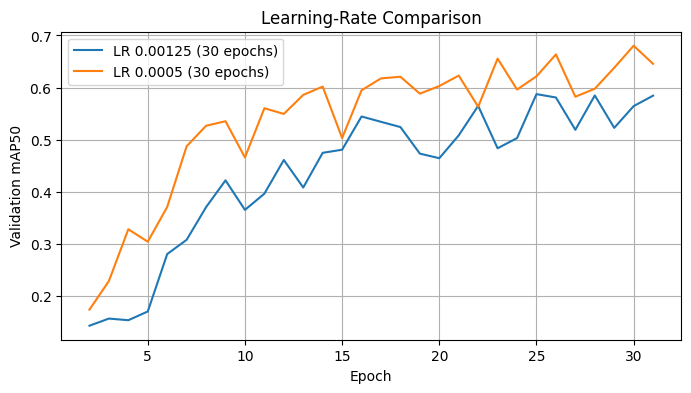

In [9]:
# Compare validation mAP50 across the two 30-epoch experiments.
labels = ("LR 0.00125 (30 epochs)", "LR 0.0005 (30 epochs)")
logs = {label: load_training_log(EXPERIMENTS[label]["folder"]) for label in labels}
if all(data is not None for data in logs.values()):
    fig, ax = plt.subplots(figsize=(8, 4))
    for label, data in logs.items():
        ax.plot(data["epoch"] + 1, data["metrics/mAP50(B)"], label=label)
    ax.set(xlabel="Epoch", ylabel="Validation mAP50", title="Learning-Rate Comparison")
    ax.legend()
    ax.grid(True)
    plt.show()
else:
    print("mAP50 plot skipped. Check the mounted Google account and RUNS_DIR.")

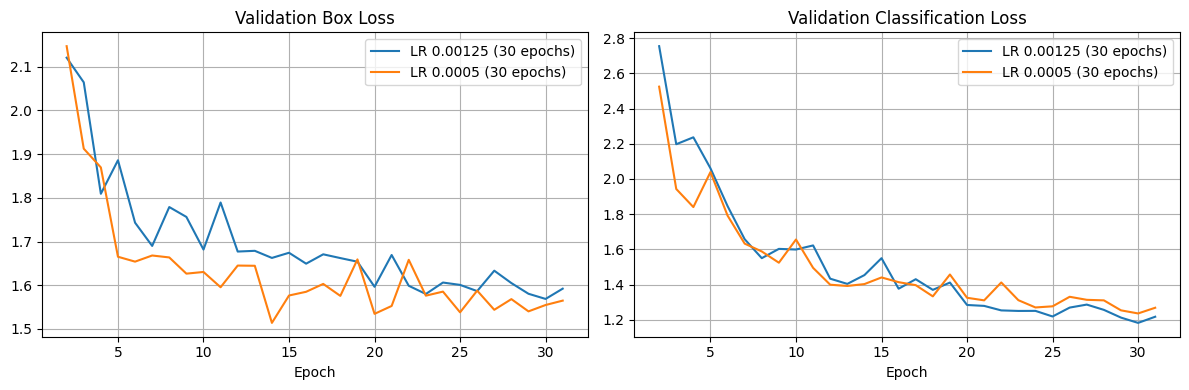

In [10]:
# Compare validation box and classification losses.
labels = ("LR 0.00125 (30 epochs)", "LR 0.0005 (30 epochs)")
logs = {label: load_training_log(EXPERIMENTS[label]["folder"]) for label in labels}
if all(data is not None for data in logs.values()):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for label, data in logs.items():
        axes[0].plot(data["epoch"] + 1, data["val/box_loss"], label=label)
        axes[1].plot(data["epoch"] + 1, data["val/cls_loss"], label=label)
    for ax, title in zip(axes, ("Validation Box Loss", "Validation Classification Loss")):
        ax.set(xlabel="Epoch", title=title)
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Loss plots skipped. Check the mounted Google account and RUNS_DIR.")

In [11]:
# Compare the 50-epoch experiment at epochs 30, 40 and 50.
data = load_training_log("v1_lr_0005_50epochs")
if data is not None:
    data["epoch_number"] = data["epoch"] + 1
    summary = data.loc[data["epoch_number"].isin([30, 40, 50]),
                       ["epoch_number", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]]
    display(summary.rename(columns={"epoch_number": "Epoch"}).round(4))
else:
    print("Epoch comparison skipped. Check the mounted Google account and RUNS_DIR.")

,Epoch,metrics/mAP50(B),metrics/mAP50-95(B)
28,30,0.6174,0.2931
38,40,0.6339,0.2768
48,50,0.6180,0.2885


## Comparison Summary
The no-mosaic model has the highest validation mAP50 (0.6952). The 30-epoch model with learning rate 0.0005 has the highest mAP50–95 (0.3354). Extending that learning rate to 50 epochs did not improve mAP50–95.

The selected no-mosaic model's test evaluation and confusion matrix are covered in `MMA3001_v1_checking.ipynb`.